# v3.1 — Kalibrasi & paket produksi

Menerapkan keputusan dari laporan v3 (hal. 10) **tanpa melatih model baru**:

| # | Keputusan v3 | Di v3.1 |
|---|---|---|
| 1 | Ganti sistem lama (`final.joblib` + `find_peaks`) dengan pipeline revisi | Paket produksi baru + panduan migrasi `BACKEND.md` |
| 2 | Tetap MicroTransformer sebagai model produksi | Bobot model final v2 dipakai apa adanya (checksum sama) |
| 3 | Hentikan pencarian arsitektur RR-only | Dicatat sebagai keputusan proyek di `README.md` root |
| 4 | Kalibrasi ulang `class_bias` dengan grid −7…+3 | **Bagian utama notebook ini** |
| 5 | Pakai protokol v3 untuk eksperimen berikutnya | Semua perbandingan di sini memakai fold, seed, dan bootstrap v3 |

Prasyarat: `../cache/dataset_v2_detector.npz` (notebook v2), OOF MicroTransformer di `../cache/oof_robust/detector_e30_r5_s2026/`
(notebook v3), dan OOF versi lama di `.../versi_lama/` (`eval_versi_lama.py`). `../v2_revisi/model_export/` **tidak diubah**;
paket baru ditulis ke `model_export/` di folder ini.

Logika perhitungan ada di `kalibrasi.py` (dipakai juga oleh pembuat laporan).

In [1]:
import json, hashlib, shutil, time, platform, subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import wfdb

import kalibrasi as K
cv = K.cv
from predictor import ECGPredictor     # dari ../v2_revisi (path ditambahkan oleh kalibrasi.py)
import hrv_core

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
OUT_DIR, NAME = Path("model_export"), "sihedaf_v3_1"
print(f"device={DEVICE} | OOF: {K.OOF_DIR.relative_to(K.REPO)}")


def fmt(r, m):
    pt, lo, hi = r[m]
    return f"{pt:.3f} [{lo:.2f}–{hi:.2f}]"

device=cuda | OOF: cache/oof_robust/detector_e30_r5_s2026


## 1. Memilih bias produksi baru

Bias produksi dipilih **sekali** pada OOF MicroTransformer gabungan 5 ulangan × 5 fold (setiap window muncul 5 kali,
diprediksi model fold yang tidak pernah melihat pasiennya). Untuk melihat stabilitasnya, bias juga dipilih ulang per
fold secara cross-fit (25 nilai). Kalau 25 nilai itu berdekatan, bias tunggal aman dipakai.

In [2]:
t0 = time.perf_counter()
d = K.load()
cal = K.fit_production_bias(d)
b_v2 = np.asarray(d.meta_v2["class_bias"])
print(f"{d.y.size:,} window, {d.patients.size} pasien | {time.perf_counter() - t0:.0f}s")
print("Bias produksi v2  :", b_v2.tolist(), " (grid −3…+3, satu partisi, notebook v2)")
print("Bias produksi baru:", cal.b_new.tolist(), " (grid −7…+3, OOF pooled v3)")

stab = pd.DataFrame({
    (grid, kelas): {"median": np.median(f[:, i]), "min": f[:, i].min(), "maks": f[:, i].max(),
                    "di batas grid": f"{np.mean((f[:, i] <= g[0]) | (f[:, i] >= g[1])):.0%}"}
    for grid, f, g in (("grid −3…+3", cal.fold_old, (-3, 3)), ("grid −7…+3", cal.fold_new, (-7, 3)))
    for i, kelas in ((1, "AFIB"), (2, "AFL"))
}).T
stab.index.names = ["grid", "bias"]
display(stab)

165,978 window, 23 pasien | 111s
Bias produksi v2  : [0.0, 2.0, -3.0]  (grid −3…+3, satu partisi, notebook v2)
Bias produksi baru: [0.0, -0.5, -4.5]  (grid −7…+3, OOF pooled v3)


median   min  maks di batas grid
grid       bias                                 
grid −3…+3 AFIB   0.25 -0.25  0.75            0%
           AFL    -3.0  -3.0  -3.0          100%
grid −7…+3 AFIB  -0.75  -1.0  0.25            0%
           AFL    -4.5  -5.5  -4.0            0%

**Cara membaca.** Dengan grid −3…+3, bias AFL **selalu** mentok di −3. Pencarian lalu "mengakali" batas itu dengan menaikkan
bias AFIB (di v2 sampai +2): tebakan AFL berkurang karena dialihkan ke AFIB, tapi banyak window Normal ikut tertebak AFIB.
Dengan grid −7…+3, bias AFL berada di tengah rentang dan bias AFIB kembali mendekati 0.

## 2. Perbandingan pada OOF dan bootstrap pasien yang sama

Semua baris memakai window uji detektor 50 Hz, fold v3, dan bobot bootstrap yang sama (`seed=2026`, 2.000×).
- **v2 produksi**: bias `[0, 2, −3]` dipasang apa adanya (seperti di backend sekarang).
- **v3.1 cross-fit**: estimasi jujur prosedur baru (bias tiap fold dipilih dari fold lain).
- **v3.1 bias tetap**: bias tunggal baru dipasang ke OOF yang juga dipakai memilihnya, jadi sedikit optimistis.

In [3]:
ev = K.evaluate(d, cal)
order = ["v1", "v2_argmax", "v2_prod", "v2_cf", "v31_cf", "v31_fixed"]
RES = pd.DataFrame([{"Varian": K.VARIANTS[k], **{m: fmt(ev.rows[k], m) for m in
                     ("Macro-F1", "AFL F1", "AFL P", "AFL R", "Normal R", "AFIB F1")}} for k in order]).set_index("Varian")
display(RES)

ref_v3 = pd.read_csv(K.OOF_DIR / "ringkasan.csv").set_index("Model").loc["MicroTransformer +bias", "Macro-F1"]
assert ref_v3.startswith(f"{ev.rows['v31_cf']['Macro-F1'][0]:.3f}"), (ref_v3, ev.rows["v31_cf"]["Macro-F1"])
print("✓ v3.1 cross-fit identik dengan 'MicroTransformer +bias' di laporan v3:", ref_v3)


def verdict(p):
    return "lebih baik" if p >= .95 else "lebih buruk" if p <= .05 else "tidak terbedakan"


PAIR = pd.DataFrame([{"Perbandingan": f"{K.VARIANTS[a]}  vs  {K.VARIANTS[b]}",
                      **{f"Δ {m}": f"{v[0]:+.3f} [{v[1]:+.2f}…{v[2]:+.2f}]" for m, v in ev.pairs[f'{a} vs {b}'].items()
                         if m in ("Macro-F1", "AFL F1", "Normal R")},
                      "P(Δ Macro-F1>0)": round(ev.pairs[f"{a} vs {b}"]["Macro-F1"][3], 2),
                      "vonis": verdict(ev.pairs[f"{a} vs {b}"]["Macro-F1"][3])} for a, b in K.PAIRS]).set_index("Perbandingan")
display(PAIR)

,Macro-F1,AFL F1,AFL P,AFL R,Normal R,AFIB F1
Varian,,,,,,
"v1 (sebelum revisi), argmax",0.744 [0.64–0.81],0.399 [0.09–0.59],0.275 [0.05–0.46],0.728 [0.37–0.98],0.903 [0.82–0.95],0.898 [0.85–0.93]
v2 tanpa bias (argmax),0.717 [0.62–0.78],0.313 [0.04–0.48],0.201 [0.02–0.35],0.711 [0.31–0.98],0.895 [0.81–0.94],0.907 [0.86–0.94]
v2 produksi: bias tetap [0; 2; −3],0.779 [0.63–0.82],0.536 [0.11–0.63],0.598 [0.10–0.73],0.487 [0.11–0.63],0.847 [0.74–0.92],0.888 [0.83–0.93]
Prosedur v2: cross-fit grid −3…+3,0.816 [0.65–0.89],0.603 [0.12–0.81],0.580 [0.10–0.77],0.630 [0.16–0.96],0.904 [0.82–0.95],0.910 [0.86–0.94]
v3.1: cross-fit grid −7…+3 (estimasi jujur),0.832 [0.67–0.92],0.647 [0.17–0.89],0.715 [0.26–0.95],0.592 [0.13–0.91],0.924 [0.84–0.97],0.909 [0.86–0.94]
v3.1: bias tetap baru (optimistis),0.837 [0.68–0.92],0.656 [0.17–0.90],0.719 [0.27–0.95],0.603 [0.14–0.91],0.926 [0.85–0.97],0.913 [0.87–0.94]


✓ v3.1 cross-fit identik dengan 'MicroTransformer +bias' di laporan v3: 0.832 [0.67–0.92]


,Δ Macro-F1,Δ AFL F1,Δ Normal R,P(Δ Macro-F1>0),vonis
Perbandingan,,,,,
v3.1: cross-fit grid −7…+3 (estimasi jujur) vs v2 produksi: bias tetap [0; 2; −3],+0.053 [+0.01…+0.12],+0.111 [+0.01…+0.31],+0.076 [+0.05…+0.11],1.00,lebih baik
"v3.1: cross-fit grid −7…+3 (estimasi jujur) vs v1 (sebelum revisi), argmax",+0.088 [+0.02…+0.16],+0.249 [+0.05…+0.47],+0.020 [+0.01…+0.03],0.98,lebih baik
"v2 produksi: bias tetap [0; 2; −3] vs v1 (sebelum revisi), argmax",+0.035 [-0.03…+0.07],+0.138 [-0.05…+0.25],-0.056 [-0.09…-0.03],0.90,tidak terbedakan
v3.1: bias tetap baru (optimistis) vs v3.1: cross-fit grid −7…+3 (estimasi jujur),+0.005 [+0.00…+0.01],+0.008 [+0.00…+0.02],+0.002 [-0.00…+0.01],1.00,lebih baik


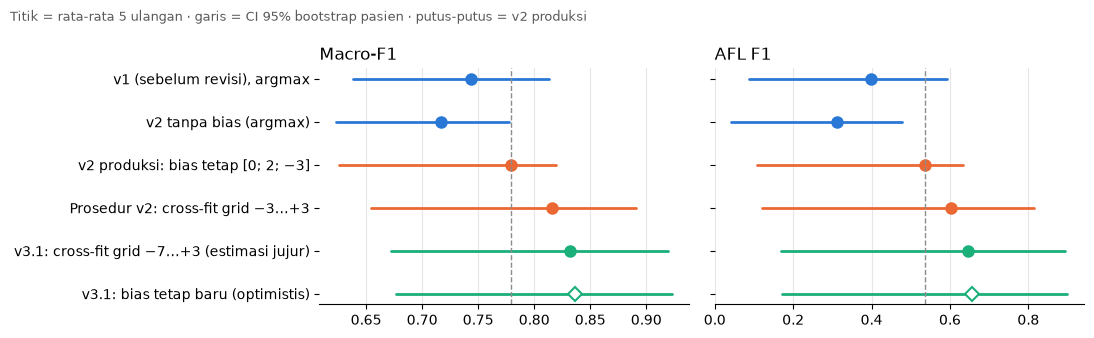

In [4]:
COLOR = {"v1": "#2a78d6", "v2_argmax": "#2a78d6", "v2_prod": "#eb6834", "v2_cf": "#eb6834",
         "v31_cf": "#1baf7a", "v31_fixed": "#1baf7a"}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, m in zip(axes, ("Macro-F1", "AFL F1")):
    for i, k in enumerate(order):
        pt, lo, hi = ev.rows[k][m]
        ax.plot([lo, hi], [i, i], color=COLOR[k], lw=2, solid_capstyle="round")
        ax.plot(pt, i, "o" if k != "v31_fixed" else "D", color=COLOR[k], mfc="white" if k == "v31_fixed" else COLOR[k],
                ms=7.5, mew=1.5)
    ax.axvline(ev.rows["v2_prod"][m][0], color="0.55", lw=1, ls="--")
    ax.set_title(m, loc="left"); ax.grid(axis="x", color="0.9"); ax.set_axisbelow(True)
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
axes[0].set_yticks(range(len(order)), [K.VARIANTS[k] for k in order]); axes[0].invert_yaxis()
fig.suptitle("Titik = rata-rata 5 ulangan · garis = CI 95% bootstrap pasien · putus-putus = v2 produksi",
             x=0.01, ha="left", fontsize=9, color="0.35")
plt.tight_layout(); plt.show()

In [5]:
AFL = pd.DataFrame({K.VARIANTS[k]: ev.afl_recall[k] for k in ("v1", "v2_prod", "v31_cf")}, index=ev.afl_patients).round(2)
AFL["window AFL"] = [int(((d.records == p) & (d.y == 2)).sum()) for p in ev.afl_patients]
AFL.index.name = "recall AFL per pasien"
display(AFL)
FP = pd.DataFrame({K.VARIANTS[k]: ev.fp_summary[k] for k in ("v1", "v2_prod", "v31_cf")}).T.round(0)
FP.columns = ["AFL palsu total", "di pasien ber-AFL", "di pasien tanpa AFL"]
display(FP)

,"v1 (sebelum revisi), argmax",v2 produksi: bias tetap [0; 2; −3],v3.1: cross-fit grid −7…+3 (estimasi jujur),window AFL
recall AFL per pasien,,,,
04043,1.00,0.20,0.40,1
04908,1.00,0.75,0.92,46
04936,0.67,0.48,0.51,673
06426,0.73,0.13,0.17,21
07910,0.21,0.00,0.00,96
08215,0.04,0.00,0.00,9
08378,1.00,0.64,0.96,306


,AFL palsu total,di pasien ber-AFL,di pasien tanpa AFL
"v1 (sebelum revisi), argmax",2240.0,1181.0,1059.0
v2 produksi: bias tetap [0; 2; −3],378.0,306.0,72.0
v3.1: cross-fit grid −7…+3 (estimasi jujur),274.0,249.0,25.0


## 3. Cek kewajaran pada model final (in-sample)

Model produksi dilatih pada **semua** pasien, jadi akurasinya tidak bisa diukur di AFDB. Yang bisa dilihat: seberapa sering
tiap kelas ditebak pada semua window detektor, dibanding proporsi sebenarnya. Ini menunjukkan arah efek bias, bukan akurasi.

In [6]:
rates = K.final_model_rates(d, K.rate_biases(ev, cal), device=DEVICE)
RATES = (pd.DataFrame(rates, index=["Normal %", "AFIB %", "AFL %"]).T * 100).round(2)
display(RATES)

,Normal %,AFIB %,AFL %
aktual,59.65,39.66,0.69
v2 [0; 2; −3],53.42,46.04,0.54
"v3.1 [0; −0,5; −4,5]",58.40,40.98,0.63


## 4. Paket produksi v3.1

Bobot (`.pt`) disalin dari v2 tanpa perubahan (checksum diverifikasi). Yang berubah di metadata: `class_bias`, versi, asal-usul
(`parent`), cara kalibrasi, dan metrik yang dilaporkan (protokol v3).

In [7]:
src_meta = K.V2_EXPORT / "sihedaf_v2.json"
src_pt = K.V2_EXPORT / "sihedaf_v2.pt"
v2_json_sha = hashlib.sha256(src_meta.read_bytes()).hexdigest()
OUT_DIR.mkdir(exist_ok=True)
dst_pt = OUT_DIR / f"{NAME}.pt"
shutil.copyfile(src_pt, dst_pt)
assert hashlib.sha256(dst_pt.read_bytes()).hexdigest() == d.meta_v2["weights_sha256"]


def _git():
    try:
        return subprocess.check_output(["git", "rev-parse", "HEAD"], stderr=subprocess.DEVNULL).decode().strip()
    except Exception:
        return None


r31 = ev.rows["v31_cf"]
meta = {k: v for k, v in d.meta_v2.items() if k not in ("class_bias", "cv_metrics", "created", "git_commit", "versions")}
meta.update({
    "version": "3.1",
    "class_bias": [float(x) for x in cal.b_new],
    "parent": {"version": "v2_revisi", "metadata": "v2_revisi/model_export/sihedaf_v2.json", "metadata_sha256": v2_json_sha,
               "class_bias": d.meta_v2["class_bias"], "cv_metrics": d.meta_v2["cv_metrics"], "versions": d.meta_v2["versions"],
               "created": d.meta_v2["created"]},
    "calibration": {
        "method": "sihedaf_cv.fit_class_bias pada OOF MicroTransformer gabungan 5 ulangan × 5 fold pasien (v3)",
        "grid": [float(cv.BIAS_GRID.min()), float(cv.BIAS_GRID.max()), 0.25],
        "oof": str(K.OOF_DIR.relative_to(K.REPO)), "n_windows_x_repeats": int(d.y.size * K.N_REPEATS),
        "fold_bias_afl_min_max": [float(cal.fold_new[:, 2].min()), float(cal.fold_new[:, 2].max())],
    },
    "cv_metrics": {
        "protokol": "v3: pooled OOF rata-rata 5 ulangan × 5 fold pasien, bias cross-fit grid −7…+3, CI 95% bootstrap pasien 2.000×",
        **{m: {"nilai": r31[m][0], "ci95": r31[m][1:]} for m in ("Macro-F1", "AFL F1", "AFL P", "AFL R", "AFIB F1", "Normal R")},
        "vs_v2_produksi_delta_macro_f1": ev.pairs["v31_cf vs v2_prod"]["Macro-F1"],
    },
    "versions": {"python": platform.python_version(), "torch": torch.__version__, "numpy": np.__version__},
    "git_commit": _git(),
    "created": time.strftime("%Y-%m-%d %H:%M:%S"),
})
(OUT_DIR / f"{NAME}.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False))
print(f"✓ {OUT_DIR / NAME}.pt (identik dengan v2) + {NAME}.json | class_bias {meta['class_bias']}")

✓ model_export/sihedaf_v3_1.pt (identik dengan v2) + sihedaf_v3_1.json | class_bias [0.0, -0.5, -4.5]


In [8]:
P31 = ECGPredictor(str(OUT_DIR), name=NAME, device="cpu")
P2 = ECGPredictor(str(K.V2_EXPORT), device="cpu")
assert hashlib.sha256(src_meta.read_bytes()).hexdigest() == v2_json_sha, "paket v2 berubah!"

# Paritas: predictor v3.1 = output mentah model + bias baru (rumus yang sama dengan evaluasi)
z = np.load(K.DATA)
idx = np.random.default_rng(0).choice(len(d.y), 4000, replace=False)
X, M = z["X"][idx], z["M"][idx]
P31.class_bias, saved = np.zeros(3, np.float32), P31.class_bias
raw = P31.predict_proba_sequences(X, M)
P31.class_bias = saved
diff = np.abs(P31.predict_proba_sequences(X, M) - cv.apply_bias(raw, cal.b_new)).max()
assert diff < 1e-5, diff
print(f"✓ Paritas predictor vs evaluasi: selisih maks {diff:.1e}")
print(f"  Prediksi berubah dibanding paket v2 pada {np.mean(P31.predict_proba_sequences(X, M).argmax(1) != P2.predict_proba_sequences(X, M).argmax(1)):.1%} "
      "dari 4.000 window acak")

try:
    P31.predict_ibi([0.8, 0.81, 0.79, 0.8, 0.82])
    raise AssertionError("guard satuan tidak bekerja")
except ValueError as e:
    print("✓ Guard satuan:", e)
print("✓ Window buruk:", P31.predict_ibi([800, 810]))

✓ Paritas predictor vs evaluasi: selisih maks 1.5e-07
  Prediksi berubah dibanding paket v2 pada 5.1% dari 4.000 window acak
✓ Guard satuan: IBI tampak dalam DETIK. Kirim dalam MILIDETIK (mis. 800, bukan 0.8).
✓ Window buruk: {'status': 'tidak_terbaca', 'reason': 'terlalu sedikit detak (2 IBI < 4)'}


In [9]:
# Demo alur end-to-end: 60 s EKG AFDB pada episode AFL (in-sample untuk model final; uji alur, bukan akurasi)
rec = "04936"
path = str(K.REPO / "data/afdb" / rec)
atr = wfdb.rdann(path, "atr")
fs = wfdb.rdheader(path).fs
start = next(s for s, a in zip(atr.sample, atr.aux_note) if a.strip("\x00").strip() == "(AFL")
sig = wfdb.rdrecord(path, channels=[0], sampfrom=int(start + 5 * fs), sampto=int(start + 65 * fs)).p_signal[:, 0]
sig50 = hrv_core.resample_signal(sig, fs, hrv_core.FS_DEVICE)        # simulasi perangkat 50 Hz
for label, P in (("v2", P2), ("v3.1", P31)):
    out = P.predict_ecg(sig50, fs=hrv_core.FS_DEVICE)
    s = out["summary"]
    per = [w.get("class_name", w["status"]).split(" ")[0] for w in out["windows"]]
    print(f"{label:<5} ringkasan: {s.get('class_name', s['status'])} ({s.get('confidence', 0):.2f}) | per window: {per}")

v2    ringkasan: AFL (Atrial Flutter) (0.76) | per window: ['AFL', 'AFL', 'AFL', 'AFL', 'AFL', 'AFL', 'AFL', 'AFL', 'AFL', 'AFL', 'AFIB']
v3.1  ringkasan: AFL (Atrial Flutter) (0.89) | per window: ['AFL', 'AFL', 'AFL', 'AFL', 'AFL', 'AFL', 'AFL', 'AFL', 'AFL', 'AFL', 'AFL']


## 5. Keputusan lain

- **Keputusan 1 (ganti sistem lama).** Panduan migrasi backend ada di `BACKEND.md`: file yang disalin, API, format keluaran,
  perbedaan dengan sistem v1, checklist, dan cara rollback ke paket v2.
- **Keputusan 2 (MicroTransformer).** Bobot v2 dipakai apa adanya. BiGRU setara di v3, tapi tidak lebih baik.
- **Keputusan 3 (stop arsitektur RR-only)** dan **5 (protokol v3)** dicatat sebagai keputusan proyek di `README.md` dan `AGENTS.md` root.

In [10]:
summary = K.assemble(d, cal, ev, rates)
K.CACHE_OUT.mkdir(parents=True, exist_ok=True)
(K.CACHE_OUT / "ringkasan.json").write_text(json.dumps(summary, indent=1, ensure_ascii=False))
p = ev.pairs["v31_cf vs v2_prod"]
print(f"Bias baru {cal.b_new.tolist()} (v2: {b_v2.tolist()})")
print(f"v3.1 vs v2 produksi: Δ Macro-F1 {p['Macro-F1'][0]:+.3f} [{p['Macro-F1'][1]:+.3f}…{p['Macro-F1'][2]:+.3f}], "
      f"P(Δ>0) = {p['Macro-F1'][3]:.2f} → {verdict(p['Macro-F1'][3])}")
print(f"Ringkasan → {K.CACHE_OUT.relative_to(K.REPO)}/ringkasan.json")

Bias baru [0.0, -0.5, -4.5] (v2: [0.0, 2.0, -3.0])
v3.1 vs v2 produksi: Δ Macro-F1 +0.053 [+0.014…+0.120], P(Δ>0) = 1.00 → lebih baik
Ringkasan → cache/v3_1/ringkasan.json


## 6. Kesimpulan

**Bias produksi baru `[0.0, -0.5, -4.5]` menggantikan `[0.0, 2.0, -3.0]`.** Bias ini stabil: 25 bias per fold berada di AFL −5,5…−4,0
dan AFIB −1,0…+0,25. Selisih antara estimasi jujur (cross-fit) dan bias tetap hanya 0,005 Macro-F1.

**Dibanding v2 produksi pada OOF dan bootstrap yang sama, v3.1 lebih baik secara konsisten:**
- Macro-F1 0,779 → 0,832 (Δ +0,053 [+0,01…+0,12], P(Δ>0) = 1,00)
- AFL F1 0,536 → 0,647, AFL recall 0,487 → 0,592, AFL precision 0,598 → 0,715
- Recall Normal 0,847 → 0,924
- AFL palsu pada pasien tanpa AFL: 72 → 25 window per ulangan

**Penyebab.** Bias AFIB +2 di v2 adalah kompensasi atas bias AFL yang mentok di −3. Akibatnya banyak window Normal ditebak
AFIB: model final menebak AFIB pada 46,0% window, padahal aslinya 39,7%. Dengan bias v3.1 angkanya 41,0%.

**Terhadap v1.** v2 produksi apa adanya ternyata *tidak terbedakan* dari v1 yang diukur ulang (P = 0,90). Dengan bias v3.1,
sistem lebih baik dari v1 secara konsisten (P = 0,98). Recall AFL masih di bawah v1 (0,59 vs 0,73), karena v1 terlalu
sering menebak AFL (precision 0,28).

**Paket.** `model_export/sihedaf_v3_1.{pt,json}`: bobot identik dengan v2, paritas predictor terhadap evaluasi 1,5e−7,
prediksi berubah pada ±5% window. Panduan migrasi backend dari sistem lama ada di `BACKEND.md`.

**Langkah berikutnya (v4):** smoothing antar-window dan ensemble MicroTransformer + BiGRU, dievaluasi pada OOF yang sama
dengan referensi baru: v3.1.